In [ ]:
# external libraries
# import spacy
import sentence_transformers
import numpy as np
from sklearn.cluster import KMeans
from collections import defaultdict
from tqdm import tqdm
import random
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

/Users/mcharit2/Desktop/Research/ModAnalysis/mod_analysis/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [36]:
# external utility file
import analysis_utils as au

## Perform Cluster analysis on JSONs

### Import data

In [37]:
# get the combined dataset for all games
def combine_datasets(games):
    game_df_list = {}
    category_counts = {}
    for game_name in games:
        df = au.load_mod_data_per_game(game_name)
        df = au.preprocess_mod_data(df)
        game_df_list[game_name] = df

    all_df = au.combine_all_games_data(game_df_list)
    return all_df

FULL_DATASET = combine_datasets(['skyrim', 'stardewvalley', 'cyberpunk2077', 'minecraft'])

In [38]:
# show the data
print(FULL_DATASET.head)
print(FULL_DATASET.columns)

<bound method NDFrame.head of          modId                          name  \
0       121473  Lydia was in Watchtower (RU)   
1       121261  Lydia was in Watchtower (EN)   
2       121474                  Salty Fus LE   
3       121472           Rumors of Skyrim LE   
4       121471     Dremora Voiced Everywhere   
...        ...                           ...   
124591      12       Mapa para PaintBall Mod   
124592       8       Stuck in the simulation   
124593       6            Storyline survival   
124594       4          Tamriel in Minecraft   
124595       5                 Starter House   

                                                  summary  downloads  \
0             Слегка меняет вашу первую встречу с Лидией.          4   
1       Fix your first meet whis your housecarl from W...          5   
2       Consuming Fire/Frost/Void salts before shoutin...          2   
3       Adds over 50 unique rumors that the citizens o...          6   
4             Adds the Dremora Lo

### Set up embedding model

In [48]:
# vectorize the categories using sentence-transformers
model = sentence_transformers.SentenceTransformer('all-MiniLM-L6-v2')

all_categories = list(FULL_DATASET['category'].unique())
category_by_game = {}
for game in FULL_DATASET['game'].unique():
    cats = set(FULL_DATASET[FULL_DATASET['game'] == game]['category'].unique())
    for cat in cats:
        if cat not in category_by_game:
            category_by_game[cat] = []
        category_by_game[cat].append(game)

category_vectors = {}
for category in all_categories:
    category_vectors[category] = {'vector':model.encode(category), 'games': category_by_game[category]}

print(f"Total unique categories: {len(all_categories)}")
print(f"Vector dimension: {len(category_vectors[all_categories[0]]['vector'])}")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9695.96it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total unique categories: 117
Vector dimension: 384


In [41]:
# test viewing some category vectors
for cat in random.choices(all_categories, k=5):
    print ("===", cat, "===")
    print(f"- Games: {category_vectors[cat]['games']}")
    print(f"- Vector: {category_vectors[cat]['vector'][:5]}...")  # print first 5 dimensions

=== Appearance Change Unlocker Preset ===
- Games: ['cyberpunk2077']
- Vector: [-0.08339541 -0.00132051  0.04051809  0.00505618 -0.02109897]...
=== NPC - Children ===
- Games: ['skyrim']
- Vector: [-0.09609593 -0.00635348 -0.0416597   0.06570636  0.02580786]...
=== Player Skins ===
- Games: ['minecraft']
- Vector: [-0.00152864  0.0728148   0.02189656 -0.02336193  0.10796499]...
=== Add-On Apartment ===
- Games: ['cyberpunk2077']
- Vector: [-0.02072809 -0.07372367 -0.00620937  0.01984763 -0.01742015]...
=== Appearance Change Unlocker Preset ===
- Games: ['cyberpunk2077']
- Vector: [-0.08339541 -0.00132051  0.04051809  0.00505618 -0.02109897]...


In [42]:
# check if any categories have zero vectors (should be none with the medium model)
for cat, dat in category_vectors.items():
    if np.all(dat['vector'] == 0):
        print(f"Category '{cat}' has a zero vector!")

### Perform K-Means Clustering

In [43]:
def kmeans_cat_spacy(
    vector_set,
    k=20,
    random_state=42,
    max_iter=300,
    n_init=20
):
    """
    Clusters categories using KMeans on spaCy vectors.

    Returns:
      - labels: dict category -> cluster_id
      - reps: dict cluster_id -> category (closest to centroid)
      - clusters: dict cluster_id -> list of categories in that cluster
    """
    # 1) Prepare data matrix
    cats = list(vector_set.keys())
    vectors = [vector_set[cat]['vector'] for cat in cats]

    X = np.vstack(vectors).astype(np.float32)

    # 2) Normalize to make KMeans behave more like cosine-based clustering
    # (KMeans uses Euclidean distance; normalization makes it correlate with cosine similarity.)
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    X = X / np.clip(norms, 1e-12, None)

    # 3) KMeans
    if k > len(cats):
        raise ValueError(f"k={k} is larger than the number of usable categories ({len(cats)}).")

    km = KMeans(
        n_clusters=k,
        random_state=random_state,
        n_init=n_init,
        max_iter=max_iter,
    )
    cluster_ids = km.fit_predict(X)
    centroids = km.cluster_centers_  # already in normalized space-ish

    # 4) Build cluster -> categories
    clusters = defaultdict(list)
    for cat, c in zip(cats, cluster_ids):
        clusters[int(c)].append(cat)

    # 5) Choose representative category per cluster: closest to centroid (cosine via dot product)
    # Since vectors are normalized, dot(X, centroid) is cosine similarity (if centroid normalized).
    reps = {}
    labels = {}
    # Normalize centroids too (good practice)
    cent_norms = np.linalg.norm(centroids, axis=1, keepdims=True)
    centroids = centroids / np.clip(cent_norms, 1e-12, None)

    # For fast rep selection, compute dot with centroid for each point
    for c in range(k):
        idxs = np.where(cluster_ids == c)[0]
        if len(idxs) == 0:
            reps[c] = None
            continue
        sims = X[idxs] @ centroids[c]  # cosine similarity
        best_local = idxs[int(np.argmax(sims))]
        reps[c] = cats[best_local]

    # category -> cluster label map
    for cat, c in zip(cats, cluster_ids):
        labels[cat] = int(c)

    return labels, reps, dict(clusters)


In [44]:
NUM_CLUSTERS = 20
labels, reps, clusters = kmeans_cat_spacy(category_vectors, k=NUM_CLUSTERS) 
print("Representative per cluster:")
for cid, rep in sorted(reps.items()):
    print(cid, rep, "size=", len(clusters[cid]))

Representative per cluster:
0 Enderal: Miscellaneous size= 8
1 Apartment size= 8
2 Characters size= 5
3 Maps size= 7
4 Items and Objects - Player size= 5
5 Creatures size= 8
6 Animations size= 6
7 NPC size= 3
8 Books and Scrolls size= 3
9 Items size= 12
10 Locations - Vanilla size= 9
11 Appearance Menu Mod Preset size= 3
12 Gameplay size= 7
13 Audio size= 4
14 Followers and Companions size= 4
15 Weapons and Armour size= 5
16 Modders Resources size= 4
17 World Save size= 2
18 Patches size= 4
19 Clothing size= 10


In [45]:
# show the groups for each cluster
for cid, cats_in_cluster in clusters.items():
    print(f"Cluster {cid} (size={len(cats_in_cluster)}):")
    for cat in cats_in_cluster:
        print(f"  - {cat} {category_vectors[cat]['games']}")

Cluster 12 (size=7):
  - Immersion ['skyrim']
  - Gameplay ['skyrim', 'cyberpunk2077']
  - Magic - Gameplay ['skyrim']
  - Combat ['skyrim']
  - Skills and Leveling ['skyrim']
  - Gameplay Mechanics ['stardewvalley']
  - Minigames ['minecraft']
Cluster 5 (size=8):
  - Shouts ['skyrim']
  - Creatures ['skyrim']
  - Livestock and Animals ['stardewvalley']
  - Crops ['stardewvalley']
  - Fishing ['stardewvalley']
  - Pets / Horses ['stardewvalley']
  - Food ['minecraft']
  - Biomes ['minecraft']
Cluster 13 (size=4):
  - Audio ['skyrim', 'stardewvalley', 'cyberpunk2077']
  - Audio - SFX, Music, and Voice ['skyrim']
  - AI Voices ['cyberpunk2077']
  - Audio Replacer ['cyberpunk2077']
Cluster 14 (size=4):
  - Followers and Companions ['skyrim']
  - Guilds/Factions ['skyrim']
  - Mounts ['skyrim']
  - Followers and Companions - Creatures ['skyrim']
Cluster 15 (size=5):
  - Armour - Shields ['skyrim']
  - Armour ['skyrim', 'minecraft']
  - Weapons and Armour ['skyrim']
  - Armour and Clothing 

### Visualize the Groups with PCA

In [50]:
def plot_clustered_vectors(vec_dict, cluster_labels=None, annotate=True, figsize=(12, 8)):
    """
    vec_dict: dict[str, np.ndarray]
        Example: {"cat": np.array([...384...]), "dog": np.array([...384...]), ...}

    cluster_labels: list or np.ndarray or None
        Cluster id for each vector in the same order as vec_dict.keys()

    annotate: bool
        Whether to draw the text label for each point
    """

    # Extract labels and vectors
    names = list(vec_dict.keys())
    X = np.array([vec_dict[name] for name in names])   # shape (n_samples, 384)

    # Reduce to 2D
    pca = PCA(n_components=2)
    X_2d = pca.fit_transform(X)

    # Plot
    plt.figure(figsize=figsize)

    if cluster_labels is None:
        plt.scatter(X_2d[:, 0], X_2d[:, 1], s=80)
    else:
        cluster_labels = np.array(cluster_labels)
        scatter = plt.scatter(
            X_2d[:, 0],
            X_2d[:, 1],
            c=cluster_labels,
            s=80
        )
        plt.colorbar(scatter, label="Cluster")

    # Add text labels
    if annotate:
        for i, name in enumerate(names):
            plt.text(X_2d[i, 0] + 0.02, X_2d[i, 1] + 0.02, name, fontsize=9)

    plt.title("Clustered Category Embeddings (PCA)")
    plt.xlabel("PC 1")
    plt.ylabel("PC 2")
    plt.grid(True, alpha=0.3)
    plt.show()

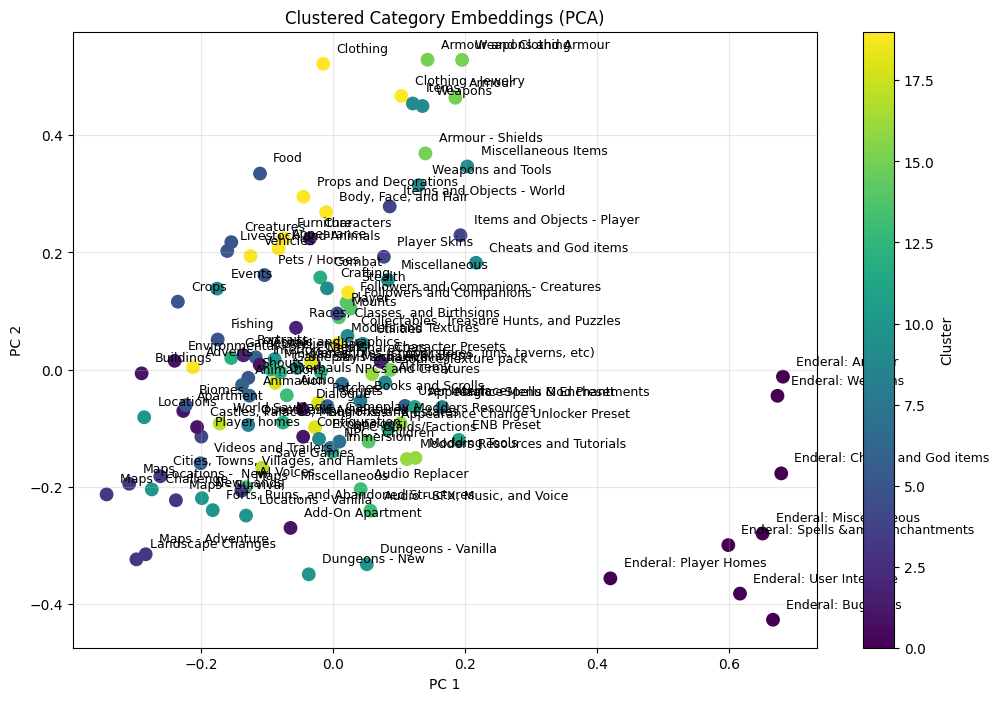

In [51]:
plot_clustered_vectors(
    {cat: dat['vector'] for cat, dat in category_vectors.items()},
    cluster_labels=[labels[cat] for cat in category_vectors.keys()]
    )

### Visualize the Groups with tSNE

In [52]:
from sklearn.manifold import TSNE

def plot_tsne_vectors(vec_dict, cluster_labels=None, annotate=True, figsize=(12, 8)):
    names = list(vec_dict.keys())
    X = np.array([vec_dict[name] for name in names])

    X_2d = TSNE(n_components=2, random_state=42, perplexity=min(30, len(X)-1)).fit_transform(X)

    plt.figure(figsize=figsize)

    if cluster_labels is None:
        plt.scatter(X_2d[:, 0], X_2d[:, 1], s=80)
    else:
        cluster_labels = np.array(cluster_labels)
        scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=cluster_labels, s=80)
        plt.colorbar(scatter, label="Cluster")

    if annotate:
        for i, name in enumerate(names):
            plt.text(X_2d[i, 0] + 0.5, X_2d[i, 1] + 0.5, name, fontsize=9)

    plt.title("Clustered Category Embeddings (t-SNE)")
    plt.grid(True, alpha=0.3)
    plt.show()

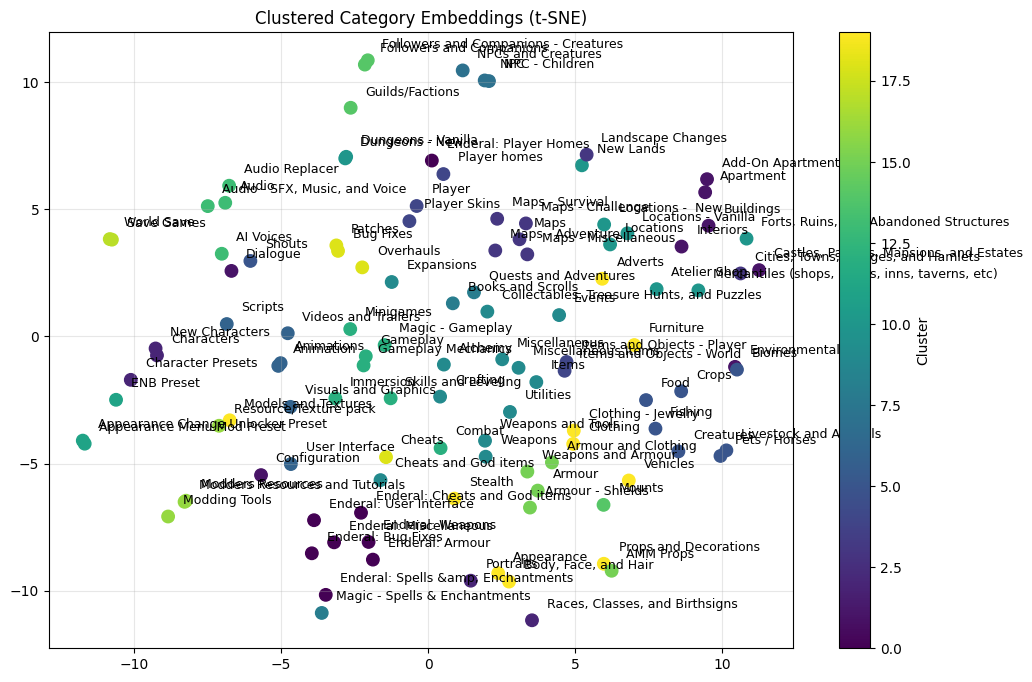

In [53]:
plot_tsne_vectors(
    {cat: dat['vector'] for cat, dat in category_vectors.items()},
    cluster_labels=[labels[cat] for cat in category_vectors.keys()]
    )